# 05 — Improved Models (Review 1 final)
Baselines in notebook 04 used ONE feature set per model. Here we make three simple, explainable improvements:

1. **Combine** TF-IDF + handcrafted features + prompt (one-hot) into a single feature matrix
2. **Tune** Ridge's `alpha` with cross-validation on the training set only
3. **Ensemble** Ridge with a Gradient Boosting model (average of the two), and clip predictions to the valid 1-6 range

Same 80/20 split and `random_state=42` as notebook 04, so results are directly comparable. Everything is fit on training data only (no leakage).

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import sys, time
sys.path.append('../src')

from models.evaluate import regression_metrics, classification_metrics, plot_confusion_matrix
from data.preprocess import add_score_category_column

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import cohen_kappa_score
from scipy.sparse import hstack, csr_matrix

sns.set_style('whitegrid')
FIG_DIR, METRICS_DIR = '../results/figures', '../results/metrics'
RANDOM_STATE = 42

df = pd.read_csv('../data/processed/essays_processed.csv')
df.shape

(24728, 16)

## 1. A few extra cheap features
Computed with plain pandas (no slow NLP): log of word count, long-word ratio (words with 7+ letters, a vocabulary-sophistication signal), commas per sentence, and paragraph count (from the *original* text, since paragraph breaks live there).

In [2]:
def long_word_ratio(text):
    words = [w for w in text.split() if w.isalpha()]
    return sum(len(w) >= 7 for w in words) / len(words) if words else 0

df['log_word_count'] = np.log1p(df['word_count'])
df['long_word_ratio'] = df['clean_text'].apply(long_word_ratio)
df['commas_per_sentence'] = df['original_text'].str.count(',') / df['sentence_count'].clip(lower=1)
df['paragraph_count'] = df['original_text'].str.count(r'\n\s*\n') + 1

base_cols = ['word_count','character_count','sentence_count','avg_word_length','avg_sentence_length',
             'sentence_length_std','unique_word_count','type_token_ratio','flesch_reading_ease','flesch_kincaid_grade']
extra_cols = ['log_word_count','long_word_ratio','commas_per_sentence','paragraph_count']
num_cols = base_cols + extra_cols

train_df, test_df = train_test_split(df, test_size=0.20, random_state=RANDOM_STATE)
y_train, y_test = train_df['score'], test_df['score']
print(len(train_df), 'train /', len(test_df), 'test')

19782 train / 4946 test


## 2. Build the combined feature matrix (fit on train only)
```
TF-IDF (words, 1-2 grams)  +  scaled handcrafted features  +  prompt one-hot
                         ->  one sparse matrix  ->  model
```
`sublinear_tf=True` dampens the effect of very frequent words, which usually helps essay text.

In [3]:
tfidf = TfidfVectorizer(max_features=10000, ngram_range=(1, 2), min_df=3, sublinear_tf=True)
scaler = StandardScaler()
onehot = OneHotEncoder(handle_unknown='ignore')

Xtr_tfidf = tfidf.fit_transform(train_df['clean_text']);  Xte_tfidf = tfidf.transform(test_df['clean_text'])
Xtr_num = scaler.fit_transform(train_df[num_cols]);        Xte_num = scaler.transform(test_df[num_cols])
Xtr_prompt = onehot.fit_transform(train_df[['prompt_name']]); Xte_prompt = onehot.transform(test_df[['prompt_name']])

X_train_comb = hstack([Xtr_tfidf, csr_matrix(Xtr_num), Xtr_prompt]).tocsr()
X_test_comb  = hstack([Xte_tfidf, csr_matrix(Xte_num), Xte_prompt]).tocsr()

# dense set (handcrafted + prompt) for gradient boosting
X_train_dense = np.hstack([Xtr_num, Xtr_prompt.toarray()])
X_test_dense  = np.hstack([Xte_num, Xte_prompt.toarray()])
print('Combined sparse:', X_train_comb.shape, '| Dense:', X_train_dense.shape)

Combined sparse: (19782, 10021) | Dense: (19782, 21)


## 3. Train improved models
- **Ridge (combined features)** with `alpha` chosen by 5-fold cross-validation on the training set
- **Gradient Boosting** (`HistGradientBoostingRegressor`) on handcrafted + prompt features
- **Ensemble** = average of the two predictions
All predictions are clipped to [1, 6] since scores can't fall outside that range.

In [4]:
results, preds = [], {}

def evaluate(name, y_pred, train_time):
    y_pred = np.clip(y_pred, 1, 6)
    m = regression_metrics(y_test, y_pred)
    m['QWK'] = round(cohen_kappa_score(y_test, np.rint(y_pred).astype(int), weights='quadratic'), 4)
    m['Model'] = name; m['Training Time (s)'] = round(train_time, 2)
    results.append(m); preds[name] = y_pred

t = time.time()
grid = GridSearchCV(Ridge(), {'alpha': [0.3, 1, 3, 10, 30]}, cv=5, scoring='neg_root_mean_squared_error')
grid.fit(X_train_comb, y_train)
print('Best Ridge alpha:', grid.best_params_)
evaluate('Ridge (TF-IDF + features + prompt)', grid.best_estimator_.predict(X_test_comb), time.time() - t)

t = time.time()
gb = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=RANDOM_STATE)
gb.fit(X_train_dense, y_train)
evaluate('Gradient Boosting (features + prompt)', gb.predict(X_test_dense), time.time() - t)

ens = (preds['Ridge (TF-IDF + features + prompt)'] + preds['Gradient Boosting (features + prompt)']) / 2
evaluate('Ensemble (Ridge + Gradient Boosting)', ens, 0)

improved = pd.DataFrame(results)[['Model','MAE','MSE','RMSE','R2','QWK','Training Time (s)']]
improved

Best Ridge alpha: {'alpha': 3}


,Model,MAE,MSE,RMSE,R2,QWK,Training Time (s)
0,Ridge (TF-IDF + features + prompt),0.4594,0.3455,0.5878,0.6756,0.7702,15.17
1,Gradient Boosting (features + prompt),0.4784,0.3955,0.6289,0.6287,0.7379,0.33
2,Ensemble (Ridge + Gradient Boosting),0.4520,0.3425,0.5852,0.6785,0.7648,0.00


**QWK (Quadratic Weighted Kappa)** is the standard metric in automated essay scoring (it was the official metric of the original ASAP competition). It measures agreement between predicted and human scores, penalizing big disagreements more; 1.0 = perfect agreement, 0 = chance.

## 4. Before vs after
Previous best baselines come from notebook 04 (`results/metrics/regression_results.csv`).

Previous best baseline: Ridge Regression [TF-IDF]  RMSE=0.672  R2=0.576
New best:               Ensemble (Ridge + Gradient Boosting)  RMSE=0.5852  R2=0.6785  QWK=0.7648


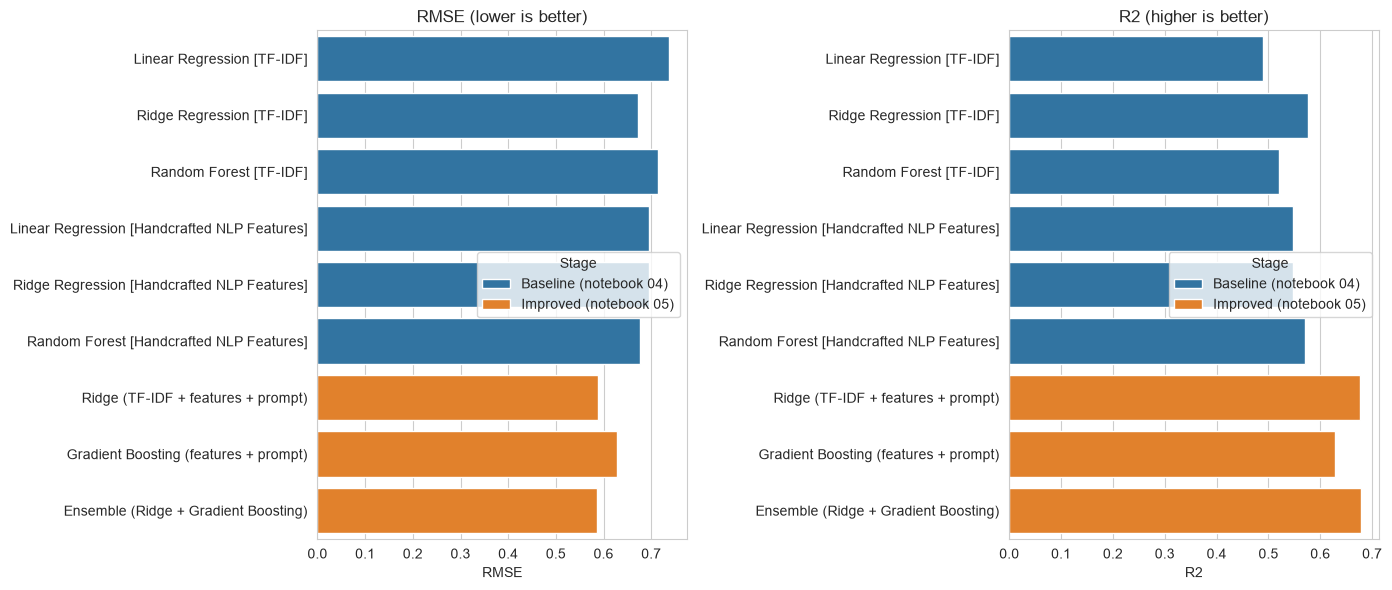

In [5]:
old = pd.read_csv(f'{METRICS_DIR}/regression_results.csv')
old['Model'] = old['Model'] + ' [' + old['Feature Set'] + ']'
old_best = old.sort_values('RMSE').iloc[0]
print(f"Previous best baseline: {old_best['Model']}  RMSE={old_best['RMSE']}  R2={old_best['R2']}")

best_new = improved.sort_values('RMSE').iloc[0]
print(f"New best:               {best_new['Model']}  RMSE={best_new['RMSE']}  R2={best_new['R2']}  QWK={best_new['QWK']}")

comparison = pd.concat([
    old[['Model','MAE','RMSE','R2']].assign(Stage='Baseline (notebook 04)'),
    improved[['Model','MAE','RMSE','R2']].assign(Stage='Improved (notebook 05)'),
], ignore_index=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, metric, title in [(axes[0], 'RMSE', 'RMSE (lower is better)'), (axes[1], 'R2', 'R2 (higher is better)')]:
    sns.barplot(data=comparison, y='Model', x=metric, hue='Stage', ax=ax)
    ax.set_title(title); ax.set_ylabel('')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/10_baseline_vs_improved.png')
plt.show()

improved.to_csv(f'{METRICS_DIR}/improved_regression_results.csv', index=False)

## 5. Secondary classification (Low / Medium / High) — improved & fairly reported
Two things here:
1. **Majority-class baseline.** If most essays are "Medium", always guessing "Medium" already scores well, so accuracy alone can look better than it really is. We report that reference number.
2. We classify using the **combined features**, and also try deriving the category from the **best regression model's predicted score** (bucketing it with the same 1-2 / 3-4 / 5-6 rule).

In [6]:
train_cat = add_score_category_column(train_df); test_cat = add_score_category_column(test_df)
y_train_cat, y_test_cat = train_cat['score_category'], test_cat['score_category']
labels = ['Low', 'Medium', 'High']

majority = y_train_cat.value_counts().idxmax()
majority_acc = (y_test_cat == majority).mean()
print(f"Majority-class baseline (always predict '{majority}'): accuracy = {majority_acc:.4f}")

t = time.time()
clf = LogisticRegression(max_iter=2000, C=3, random_state=RANDOM_STATE)
clf.fit(X_train_comb, y_train_cat)
pred_clf = clf.predict(X_test_comb)
m_clf = classification_metrics(y_test_cat, pred_clf); m_clf['Method'] = 'Logistic Regression (combined features)'

best_pred = preds[best_new['Model']]
pred_from_reg = pd.Series(best_pred).apply(lambda s: 'Low' if s < 2.5 else ('Medium' if s < 4.5 else 'High')).values
m_reg = classification_metrics(y_test_cat, pred_from_reg); m_reg['Method'] = f"Best regression model -> bucketed"

clf_table = pd.DataFrame([m_clf, m_reg])[['Method','Accuracy','Precision','Recall','F1']]
clf_table.loc[len(clf_table)] = ['Majority-class baseline', round(majority_acc, 4), np.nan, np.nan, np.nan]
clf_table

Majority-class baseline (always predict 'Medium'): accuracy = 0.5831


,Method,Accuracy,Precision,Recall,F1
0,Logistic Regression (combined features),0.7978,0.7966,0.7978,0.7946
1,Best regression model -> bucketed,0.8140,0.8138,0.8140,0.8097
2,Majority-class baseline,0.5831,NaN,NaN,NaN


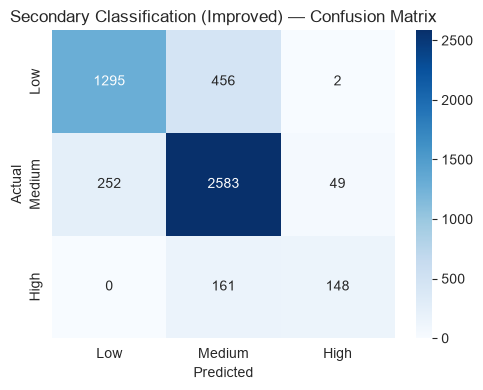

In [7]:
best_method_pred = pred_from_reg if m_reg['Accuracy'] >= m_clf['Accuracy'] else pred_clf
cm = plot_confusion_matrix(y_test_cat, best_method_pred, labels,
    title='Secondary Classification (Improved) — Confusion Matrix',
    save_path=f'{FIG_DIR}/11_confusion_matrix_improved.png')
clf_table.to_csv(f'{METRICS_DIR}/improved_classification_results.csv', index=False)

In [8]:
import joblib
bundle = {
    'tfidf': tfidf, 'scaler': scaler, 'onehot': onehot,
    'ridge': grid.best_estimator_, 'gb': gb, 'num_cols': num_cols,
}
joblib.dump(bundle, '../results/models/essay_scorer.joblib')
print('Saved results/models/essay_scorer.joblib')

Saved results/models/essay_scorer.joblib
